In [7]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


--- CIRCUITO RC ---
a) Constante de tempo tau: 1.00 s

b) Tabela de Resultados do Circuito RC:


<>:83: SyntaxWarning: invalid escape sequence '\m'
<>:83: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_138545/2853054373.py:83: SyntaxWarning: invalid escape sequence '\m'
  axes[2].set_ylabel('$i(t)$ [$\mu$A]', fontweight='bold')


,Tempo t (s),vc [V],vr [V],i [uA]
0,0.0,0.0000,10.0000,100.0000
1,0.4,3.2968,6.7032,67.0320
2,0.6,4.5119,5.4881,54.8812
3,1.0,6.3212,3.6788,36.7879
4,1.5,7.7687,2.2313,22.3130
5,2.0,8.6466,1.3534,13.5335
6,3.0,9.5021,0.4979,4.9787
7,4.0,9.8168,0.1832,1.8316
8,5.0,9.9326,0.0674,0.6738
9,6.0,9.9752,0.0248,0.2479



e) Instante matemático para vc = 5V: 0.6931 s



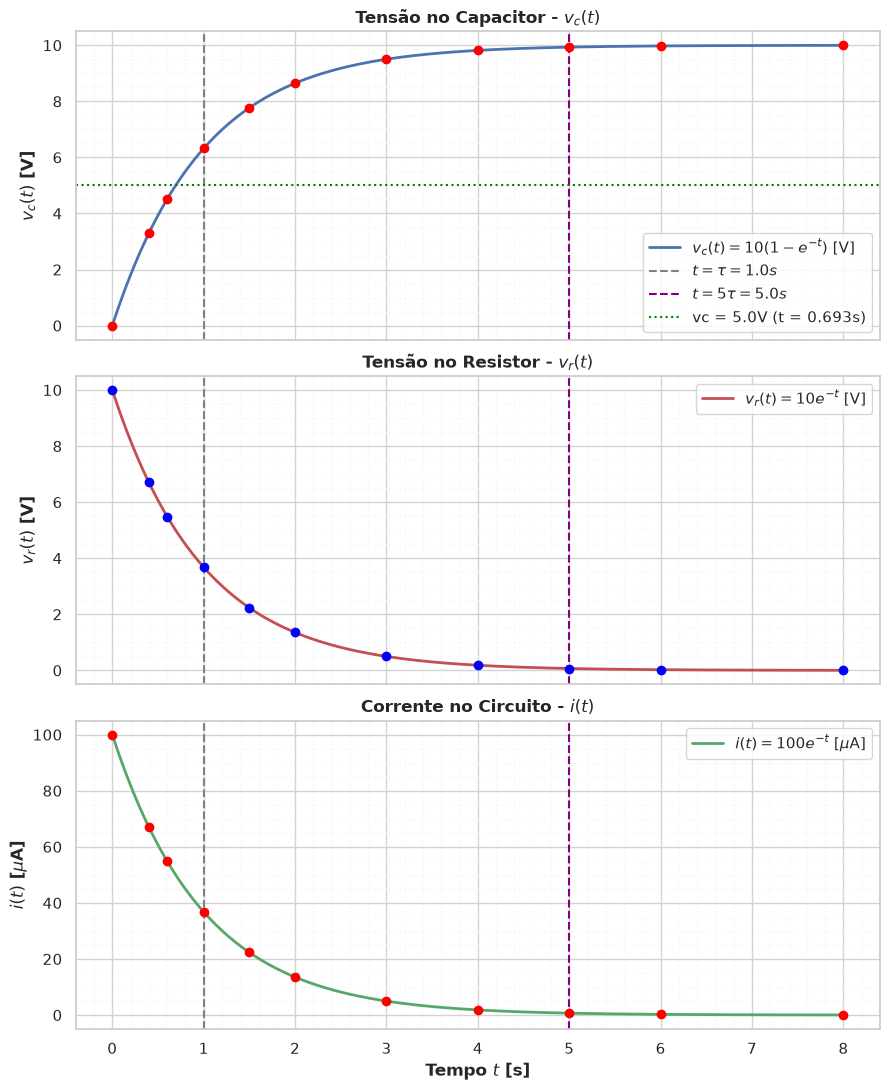


--- CIRCUITO RL ---
Constante de tempo tau (RL): 1.00 ms
a) Tempo para corrente atingir valor máximo (5*tau): 5.00 ms (0.005 s)
b) Valor máximo da corrente (I_max = E/R): 0.100 A (100.0 mA)



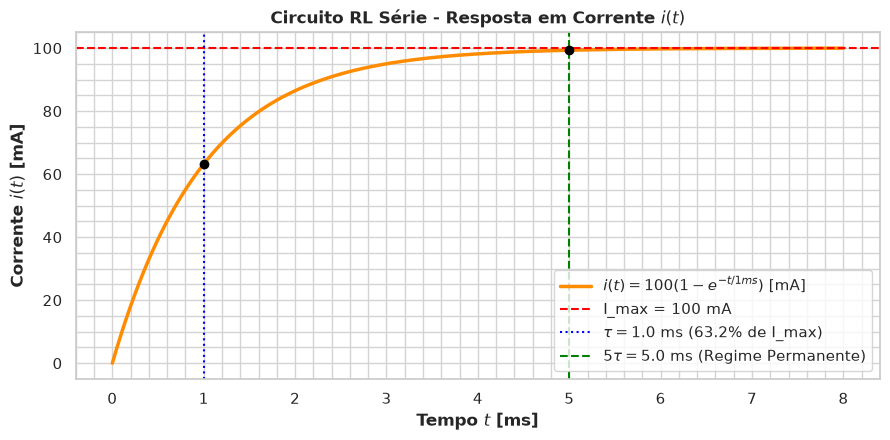

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# =============================================================
# EXERCÍCIO 1: CIRCUITO RC SÉRIE
# =============================================================
R_rc = 100e3  # 100 kOhms
C_rc = 10e-6   # 10 uF
E_rc = 10.0    # 10 Volts

# a) Constante de tempo
tau_rc = R_rc * C_rc
print(f"--- CIRCUITO RC ---")
print(f"a) Constante de tempo tau: {tau_rc:.2f} s\n")

# b) Instantes para cálculo
t_instantes = np.array([0.0, 0.4, 0.6, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0])

vc_vals = E_rc * (1 - np.exp(-t_instantes / tau_rc))
vr_vals = E_rc * np.exp(-t_instantes / tau_rc)
i_vals_uA = (E_rc / R_rc) * np.exp(-t_instantes / tau_rc) * 1e6 # em uA

# Tabela
df_rc = pd.DataFrame({
    'Tempo t (s)': t_instantes,
    'vc [V]': np.round(vc_vals, 4),
    'vr [V]': np.round(vr_vals, 4),
    'i [uA]': np.round(i_vals_uA, 4)
})

print("b) Tabela de Resultados do Circuito RC:")
display(df_rc)

# e) Cálculo matemático para vc = 5V
t_5V_mat = tau_rc * np.log(2)
print(f"\ne) Instante matemático para vc = 5V: {t_5V_mat:.4f} s\n")

# c) Gráficos no formato 'Folha Milimetrada'
t_cont = np.linspace(0, 8, 500)
vc_cont = E_rc * (1 - np.exp(-t_cont / tau_rc))
vr_cont = E_rc * np.exp(-t_cont / tau_rc)
i_cont_uA = (E_rc / R_rc) * np.exp(-t_cont / tau_rc) * 1e6

fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=True)

# Graph 1: vc(t)
axes[0].plot(t_cont, vc_cont, 'b-', linewidth=2, label=r'$v_c(t) = 10(1 - e^{-t})$ [V]')
axes[0].scatter(t_instantes, vc_vals, color='red', zorder=5)
axes[0].axvline(1.0, color='gray', linestyle='--', label=r'$t = \tau = 1.0s$')
axes[0].axvline(5.0, color='purple', linestyle='--', label=r'$t = 5\tau = 5.0s$')
axes[0].axhline(5.0, color='green', linestyle=':', label=f'vc = 5.0V (t = {t_5V_mat:.3f}s)')
axes[0].set_ylabel('$v_c(t)$ [V]', fontweight='bold')
axes[0].set_title('Tensão no Capacitor - $v_c(t)$', fontweight='bold')
axes[0].grid(True, which='both', color='lightgrey', linestyle='-')
axes[0].minorticks_on()
axes[0].grid(True, which='minor', color='whitesmoke', linestyle=':')
axes[0].legend(loc='lower right')

# Graph 2: vr(t)
axes[1].plot(t_cont, vr_cont, 'r-', linewidth=2, label=r'$v_r(t) = 10 e^{-t}$ [V]')
axes[1].scatter(t_instantes, vr_vals, color='blue', zorder=5)
axes[1].axvline(1.0, color='gray', linestyle='--')
axes[1].axvline(5.0, color='purple', linestyle='--')
axes[1].set_ylabel('$v_r(t)$ [V]', fontweight='bold')
axes[1].set_title('Tensão no Resistor - $v_r(t)$', fontweight='bold')
axes[1].grid(True, which='both', color='lightgrey', linestyle='-')
axes[1].minorticks_on()
axes[1].grid(True, which='minor', color='whitesmoke', linestyle=':')
axes[1].legend(loc='upper right')

# Graph 3: i(t)
axes[2].plot(t_cont, i_cont_uA, 'g-', linewidth=2, label=r'$i(t) = 100 e^{-t}$ [$\mu$A]')
axes[2].scatter(t_instantes, i_vals_uA, color='red', zorder=5)
axes[2].axvline(1.0, color='gray', linestyle='--')
axes[2].axvline(5.0, color='purple', linestyle='--')
axes[2].set_xlabel('Tempo $t$ [s]', fontweight='bold')
axes[2].set_ylabel('$i(t)$ [$\mu$A]', fontweight='bold')
axes[2].set_title('Corrente no Circuito - $i(t)$', fontweight='bold')
axes[2].grid(True, which='both', color='lightgrey', linestyle='-')
axes[2].minorticks_on()
axes[2].grid(True, which='minor', color='whitesmoke', linestyle=':')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

# =============================================================
# EXERCÍCIO 2: CIRCUITO RL SÉRIE
# =============================================================
R_rl = 100.0   # Ohms
L_rl = 100e-3  # 100 mH = 0.1 H
E_rl = 10.0    # Volts

tau_rl = L_rl / R_rl
t_max_rl = 5 * tau_rl
I_max_rl = E_rl / R_rl

print(f"\n--- CIRCUITO RL ---")
print(f"Constante de tempo tau (RL): {tau_rl*1000:.2f} ms")
print(f"a) Tempo para corrente atingir valor máximo (5*tau): {t_max_rl*1000:.2f} ms ({t_max_rl:.3f} s)")
print(f"b) Valor máximo da corrente (I_max = E/R): {I_max_rl:.3f} A ({I_max_rl*1000:.1f} mA)\n")

# Gráfico da curva de elevação da corrente RL
t_rl_ms = np.linspace(0, 8, 500)
i_rl_mA = (E_rl / R_rl) * (1 - np.exp(-(t_rl_ms * 1e-3) / tau_rl)) * 1000

plt.figure(figsize=(9, 4.5))
plt.plot(t_rl_ms, i_rl_mA, color='darkorange', linewidth=2.5, label=r'$i(t) = 100(1 - e^{-t/1ms})$ [mA]')
plt.axhline(100, color='red', linestyle='--', label=f'I_max = 100 mA')
plt.axvline(1.0, color='blue', linestyle=':', label=r'$\tau = 1.0$ ms (63.2% de I_max)')
plt.axvline(5.0, color='green', linestyle='--', label=r'$5\tau = 5.0$ ms (Regime Permanente)')
plt.scatter([1.0, 5.0], [63.212, 99.326], color='black', zorder=5)

plt.title('Circuito RL Série - Resposta em Corrente $i(t)$', fontweight='bold')
plt.xlabel('Tempo $t$ [ms]', fontweight='bold')
plt.ylabel('Corrente $i(t)$ [mA]', fontweight='bold')
plt.grid(True, which='both', color='lightgrey', linestyle='-')
plt.minorticks_on()
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()